# Tarea 1.2 Configuración del ambiente de trabajo (Proyecto)

## 1. Creación del ambiente de trabajo del proyecto

A continuacion se configura un ambiente de trabajo para el proyecto de la clase Temas Selectos de Física Computacional, este ambiente esta enfocado en Física de Materiales y se mostraran resultados de pruebas que corroboran el correcto funcionamiento del ambiente de trabajo.

## 2. Herramientas
Esta guia esta enfocada en el sistema operativo Windows 10 y hara uso de los programas: Miniconda, Visual Studio Code, jupyter y Python 3.12.

## 3. Creacion del ambiente de trabajo

Para la creacion del ambiente de trabajo se siguen exactamente los mismo pasos que en 01_Ambiente_Clase.ipynb.
Se debe de realizar lo mismo hasta el paso 4.

Una vez llegado al paso 4.1 se creara el ambiente pero con python 3.12
y se sehuiran los pasos hasta 5

Se adjunta evidencia de la correcrta creacion del ambiente de trabajo: 

![Ambientes de trabajo](<Capturas/mat1.png>)


# 5. Instalar las bibliotecas científicas

Se instalaran las bibliotecas científicas generales ejecutando: 

```bash
conda install -c conda-forge --override-channels numpy scipy matplotlib pandas jupyterlab notebook ipykernel -y
```

Posteriormente se instalan las bibliotecas especializadas de Materiales ejecutando: 

```bash
conda install -c conda-forge --override-channels ase pymatgen spglib phonopy seekpath -y
```

Una vez realizado se debe ejecutar el siguiente comando para verificar que las cinco bibliotecas pueden importarse:

```bash
python -c "import ase, spglib, phonopy, seekpath; from pymatgen.core import Structure; print('Bibliotecas de materiales instaladas CORRECTAMENTE')"
```

 **¿Por qué estas bibliotecas?**
Las bibliotecas principales son:

| Biblioteca | Función |
|---|---|
| `pymatgen` | Analizar materiales y estructuras cristalinas |
| `ase` | Crear, manipular y analizar estructuras atómicas |
| `spglib` | Determinar grupos espaciales y simetrías cristalinas |
| `phonopy` | Preparar y realizar cálculos de propiedades vibracionales a partir de fuerzas interatómicas |
| `seekpath` | Obtener trayectorias de alta simetría en el espacio recíproco |


Se muestra la salida de estos comandos: 

![Ambientes de trabajo](<Capturas/mat2.png>)

## 6. Registrar el ambiente como kernel de Jupyter
se seguiran los pasos del primer notebook para registrar el ambiente como kernel de Jupyter y posterior pasaremos hasta el paso 11 y 12.
se adjuntan capturas de las salidas de llevar a cabo este proceso:

![Ambientes de trabajo](<Capturas/mat3.png>)

Salida de Terminal de VSC:
![Ambientes de trabajo](<Capturas/mat4.png>)


## 7. Pruebas
A cntinuacion ya con el kernel seleccionado se ejecutaran los siguientes ejemplos para ver el correcto funcionamiento de las bibliotecas instaladas 

## Ejemplo 1: construir una estructura cristalina con ASE
Se construira una celda convencional cúbica de silicio con estructura de diamante y parámetro de red aproximado de 5.431 Å.

ASE permite consultar los vectores de red, las posiciones de los átomos y la composición.

In [4]:
from ase.build import bulk

silicio = bulk("Si", "diamond", a=5.431, cubic=True)

print("Fórmula de la celda:", silicio.get_chemical_formula())
print("Número de átomos:", len(silicio))
print("Vectores de la celda (Å):\n", silicio.cell.array)
print("Volumen de la celda (Å³):", round(silicio.get_volume(), 3))
print("Primeras posiciones atómicas (Å):\n", silicio.positions[:4])

Fórmula de la celda: Si8
Número de átomos: 8
Vectores de la celda (Å):
 [[5.431 0.    0.   ]
 [0.    5.431 0.   ]
 [0.    0.    5.431]]
Volumen de la celda (Å³): 160.191
Primeras posiciones atómicas (Å):
 [[0.      0.      0.     ]
 [1.35775 1.35775 1.35775]
 [0.      2.7155  2.7155 ]
 [1.35775 4.07325 4.07325]]


## Ejemplo 2: grupo espacial con spglib
A partir de los vectores de red, posiciones fraccionarias y números atómicos, spglib identifica las simetrías de la estructura.

(Para el silicio ideal en estructura diamante se espera el grupo espacial Fd-3m (número 227).)


In [6]:
import spglib

celda_spglib = (
    silicio.cell.array,
    silicio.get_scaled_positions(),
    silicio.get_atomic_numbers(),
)

datos_simetria = spglib.get_symmetry_dataset(celda_spglib, symprec=1e-5)
if datos_simetria is None:
    raise RuntimeError("spglib no logró identificar la simetría")

print("Grupo espacial:", datos_simetria.international)
print("Número de grupo espacial:", datos_simetria.number)
print("Número de operaciones de simetría:", len(datos_simetria.rotations))

Grupo espacial: Fd-3m
Número de grupo espacial: 227
Número de operaciones de simetría: 192


## Ejemplo 3: convertir a pymatgen y simular difracción de rayos X
Se usa pymatgen para construir un patrón teórico de difracción de polvo del silicio. La longitud de onda seleccionada es Cu Kα. 

Fórmula reducida: Si
Número de sitios: 8


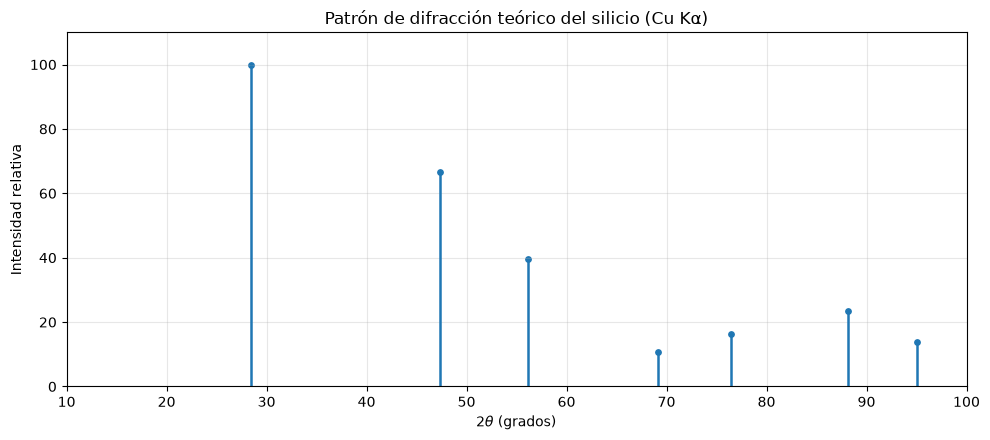

Picos calculados: 7
Primeros ángulos 2θ: [28.46547674 47.34269082 56.17098486 69.1928388  76.44797051]


In [7]:
import matplotlib.pyplot as plt
from pymatgen.io.ase import AseAtomsAdaptor
from pymatgen.analysis.diffraction.xrd import XRDCalculator

estructura = AseAtomsAdaptor.get_structure(silicio)
print("Fórmula reducida:", estructura.composition.reduced_formula)
print("Número de sitios:", len(estructura))

calculadora = XRDCalculator(wavelength="CuKa")
patron = calculadora.get_pattern(estructura, two_theta_range=(10, 100))

plt.figure(figsize=(10, 4.5))
plt.vlines(patron.x, 0, patron.y, linewidth=1.8)
plt.scatter(patron.x, patron.y, s=15)
plt.xlabel(r"$2\theta$ (grados)")
plt.ylabel("Intensidad relativa")
plt.title("Patrón de difracción teórico del silicio (Cu Kα)")
plt.xlim(10, 100)
plt.ylim(0, 110)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Picos calculados:", len(patron.x))
print("Primeros ángulos 2θ:", patron.x[:5])

## Ejemplo 4: camino de alta simetría con SeeK-path
Los cálculos de estructura de bandas electrónicas y dispersión de fonones suelen representarse sobre trayectorias seleccionadas en la zona de Brillouin. seekpath permite obtener las trayectorias a partir de la estructura cristalina, sin calcular las energías electrónicas.

In [8]:
import seekpath

ruta = seekpath.get_path(celda_spglib)
print("Tipo de red de Bravais:", ruta["bravais_lattice"])
print("Primeros segmentos de alta simetría:")
for tramo in ruta["path"][:8]:
    print("  ", tramo)

print("Puntos especiales disponibles:", list(ruta["point_coords"].keys()))

Tipo de red de Bravais: cF
Primeros segmentos de alta simetría:
   ('GAMMA', 'X')
   ('X', 'U')
   ('K', 'GAMMA')
   ('GAMMA', 'L')
   ('L', 'W')
   ('W', 'X')
Puntos especiales disponibles: ['GAMMA', 'X', 'L', 'W', 'W_2', 'K', 'U']


## Ejemplo 5: preparar desplazamientos para fonones con Phonopy
Se construye una supercelda y genera desplazamientos atómicos pequeños.

In [10]:
import numpy as np
from phonopy import Phonopy
from phonopy.structure.atoms import PhonopyAtoms

unidad = PhonopyAtoms(
    symbols=silicio.get_chemical_symbols(),
    cell=silicio.cell.array,
    scaled_positions=silicio.get_scaled_positions(),
)

fonones = Phonopy(unidad, supercell_matrix=np.diag([2, 2, 2]))
fonones.generate_displacements(distance=0.01)

print("Número de átomos en la supercelda:", len(fonones.supercell))
print("Superceldas con desplazamientos:", len(fonones.supercells_with_displacements))


Número de átomos en la supercelda: 64
Superceldas con desplazamientos: 1
